<a href="https://colab.research.google.com/github/mjcolebank/MATH328_UofSC/blob/main/Example1_PDFs_and_CDFs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## This is an example of how we can approximate the probability and cumulative density functions (PDF and CDF, respectively) given some data.

Recall that the PDF reprsents a functional mapping from some observable (e.g., $\omega$) to the some value in the real number, $\mathbb{R}$. The PDF is a probability density because it satisfies
\begin{align}
\int_{\omega\in\Omega}f_X(\omega)d\omega = 1
\end{align}

Since this is our first exposure to using Python/Jupyter/Colab, let's walk through how we use the software.

First, we are going to import libraries. In Python, we are lucky to have built in functions and applications so that we don't have to code things all from scratch. For example, if we want to generate a PDF, we don't have to define it in algorithm form. Rather, we can just tell a package's "pdf" function to make a pdf, given some observations.

Below, we see four packages uploaded:

-- matplotlib: our way of plotting things

-- scipy: scientific functions in python

-- numpy: our default way of handling vectors and matrices (discussed later in the course)

-- math: a nice package for defining basic mathematical objects (e.g., sine, cosine, pi)


Here you will also see that we are doing two things:

(1) 'importing' whole libraries of functions an naming them something more convenient (e.g., plt for matplotlib)

(2) grabbing specific functions from libraries. For example, scipy has a statistics toolbox, scipy.stats, and a function 'norm' that can generate normal distributions.

First, we install the packages (in colab) using 'pip'


In [ ]:
! pip install matplotlib
! pip install scipy
! pip install numpy


In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import norm
import numpy as np
import math


Next, we can define properties of our data. Most distributions have specific parameters that describe them. For a normal distribution (Gaussian), the mean and variance (or standard deviation) are most important. Note that we are using the 'math' library's function 'sqrt' to get the square root, and we use the 'numpy' libraries 'linspace' to generate a vector of numbers that are equispaced on the interval -3 to 3. The three arguments in that function are the lower value, upper value, and total number of points you want (here, 201)

In [ ]:
mean = 0
variance = 1
sigma = math.sqrt(variance)
x = np.linspace(-3, 3, 201)


Finally, we can plot the PDF and CDF by using the built in capabilities of scipy's 'norm' function. You can find out what this does by running the following below

In [9]:
help(norm)

Help on norm_gen in module scipy.stats._continuous_distns:

<scipy.stats._continuous_distns.norm_gen object>
    A normal continuous random variable.

    The location (``loc``) keyword specifies the mean.
    The scale (``scale``) keyword specifies the standard deviation.

    As an instance of the `rv_continuous` class, `norm` object inherits from it
    a collection of generic methods (see below for the full list),
    and completes them with details specific for this particular distribution.

    Methods
    -------
    rvs(loc=0, scale=1, size=1, random_state=None)
        Random variates.
    pdf(x, loc=0, scale=1)
        Probability density function.
    logpdf(x, loc=0, scale=1)
        Log of the probability density function.
    cdf(x, loc=0, scale=1)
        Cumulative distribution function.
    logcdf(x, loc=0, scale=1)
        Log of the cumulative distribution function.
    sf(x, loc=0, scale=1)
        Survival function  (also defined as ``1 - cdf``, but `sf` is sometim

Now we can generate the PDF and CDF by assigning values from this function, and then plotting. To do this, we 'standarize' the values you generated in x by the mean and variance. For instance, if x runs from -3 to 3, but your mean is 5 and variance is 0.2, we can generate values that a PDF generator can understand and plot for you.

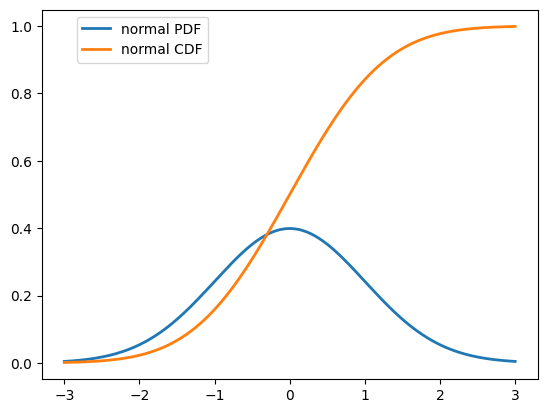

In [11]:
stand_x = (x - mean)/sigma

pdf_values = norm.pdf(stand_x)
cdf_values = norm.cdf(stand_x)
plt.plot(x, pdf_values,linewidth=2.0, label='normal PDF')
plt.plot(x, cdf_values,linewidth=2.0, label='normal CDF')
plt.legend(bbox_to_anchor=(.35,1))
plt.show()

Now, consider the case when the mean and variance are different. Experiment with different means and variances.

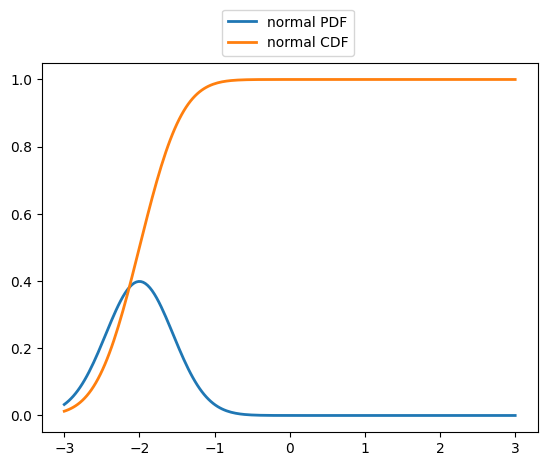

In [15]:
mean = -2
variance = 0.2
sigma = math.sqrt(variance)
x = np.linspace(-3, 3, 201)

stand_x = (x - mean)/sigma

pdf_values = norm.pdf(stand_x)
cdf_values = norm.cdf(stand_x)
plt.plot(x, pdf_values,linewidth=2.0, label='normal PDF')
plt.plot(x, cdf_values,linewidth=2.0, label='normal CDF')
plt.legend(bbox_to_anchor=(.35,1))
plt.show()


Let's conclude by looking at how this works if you have some data. Here, we would want to calculate the mean and standard deviation from the observations.

In [23]:
observation_data = np.array([-1.1,-2.0,0.1,-3.1,-2.5,0.2,-0.5,-0.8,-0.2,-0.3,-1.1,-1.4,-3.2,-1.1,-1.3])

observation_mean = np.mean(observation_data) # Calculate the mean
observation_std = np.std(observation_data) # Calculate the standard deviation

print(observation_mean)
print(observation_std)

-1.22
1.0367899176464503


Now we can try to visualize this if the mean and standard deviation are the true properties of the distribution.

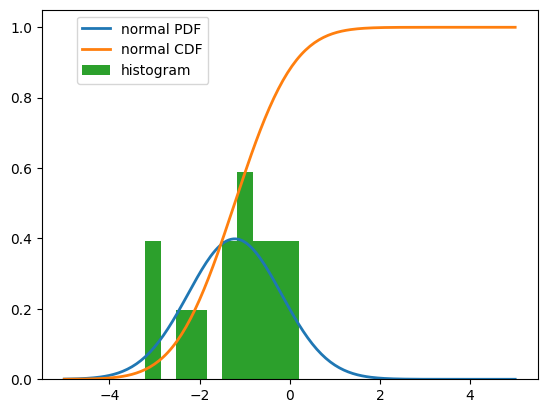

In [24]:
mean = observation_mean
sigma = observation_std
x = np.linspace(-5, 5, 201)

stand_x = (x - mean)/sigma

pdf_values = norm.pdf(stand_x)
cdf_values = norm.cdf(stand_x)
plt.plot(x, pdf_values,linewidth=2.0, label='normal PDF')
plt.plot(x, cdf_values,linewidth=2.0, label='normal CDF')
plt.hist(observation_data,density=True,label='histogram')
plt.legend(bbox_to_anchor=(.35,1))
plt.show()